# Customer Churn Prediction

A telecom company is losing customers to competitors. The sales and marketing team wants to know **which customers are likely to leave next month**, so they can offer them an incentive to stay.

- **Data:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn): 7,043 customers, 19 features, target `Churn` (Yes/No)
- **Code:** the logic lives in the `telco_churn` package (`src/telco_churn/`). This notebook calls it and explains the decisions.

**Result in short:** an L1-regularised logistic regression ranks customers by churn risk with **ROC-AUC 0.84** and **PR-AUC 0.64** on unseen test customers. Flagging everyone with a churn probability of 31% or more reaches **3 of every 4 customers who will leave**.

1. Loading and cleaning the data
2. Exploratory analysis
3. Feature engineering and preprocessing
4. Model training
5. Evaluation
6. Serving the model through a REST API

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from telco_churn.data import (
    CATEGORICAL_COLUMNS,
    NUMERIC_COLUMNS,
    TARGET,
    clean_data,
    load_raw_data,
    split_features_target,
)
from telco_churn.evaluate import (
    choose_threshold,
    evaluation_metrics,
    feature_importance,
    out_of_fold_proba,
    threshold_table,
)
from telco_churn.features import add_features, build_preprocessor
from telco_churn.model import (
    candidate_models,
    cross_validate_models,
    load_model,
    save_model,
    split_train_test,
    train_model,
)
from telco_churn.plots import (
    churn_rate_gaps,
    plot_calibration,
    plot_churn_rate,
    plot_churn_rate_gaps,
    plot_churn_rate_grid,
    plot_confusion_matrix,
    plot_feature_importance,
    plot_numeric_by_churn,
    plot_roc_pr_curves,
    plot_target_distribution,
    plot_threshold_tradeoff,
    set_style,
)

set_style()

## 1. Loading and cleaning the data

In [2]:
raw = load_raw_data()
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

TotalCharges should be a number, but it was read as text (`str`), so some of its values can't be parsed as numbers. Which ones?

In [4]:
unparseable = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
values = raw.loc[unparseable, "TotalCharges"].unique().tolist()

print(f"Not a number: {unparseable.sum()} rows, values {values}")
print(f"Same rows as tenure == 0: {(unparseable == (raw['tenure'] == 0)).all()}")
raw.loc[unparseable, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Not a number: 11 rows, values [' ']
Same rows as tenure == 0: True


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All 11 are a blank `" "`, and they are exactly the customers with tenure 0: **new customers who haven't been billed yet**. Their true total is **0**, not an unknown value, so we fill in 0 instead of dropping the rows or making up an average.

In [5]:
raw.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

customerID is different for every row, and SeniorCitizen is stored as 0/1 while the other yes/no columns use "No"/"Yes". `clean_data` fixes all of this on a copy of the data:

| Column | Change | Reason |
|---|---|---|
| TotalCharges | text → number, blanks → 0 | new customers, not billed yet |
| SeniorCitizen | 0/1 → "No"/"Yes" | same form as the other yes/no columns, so it's encoded as a category and not scaled as a number |
| Churn | "No"/"Yes" → 0/1 | scikit-learn treats 1 as the positive class, and the churn rate is then simply the mean |
| customerID | dropped | unique per customer, says nothing about churn |

After cleaning, tenure, MonthlyCharges and TotalCharges are the 3 numeric features. The other 16 are categories with 2–4 values.

In [6]:
df = clean_data(raw)
assert df.isna().sum().sum() == 0, "cleaning left missing values"

X, y = split_features_target(df)
print(f"X: {X.shape}, y: {y.shape}, churn rate: {y.mean():.1%}")

X: (7043, 19), y: (7043,), churn rate: 26.5%


## 2. Exploratory analysis

Three questions: how many customers churn, which customers churn, and what that means for the model.

### 2.1 How many customers churn?

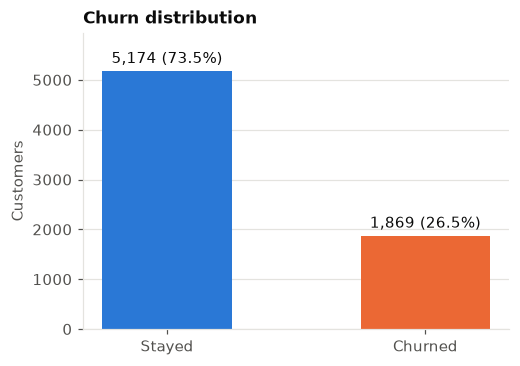

In [7]:
plot_target_distribution(y)
plt.show()

**26.5% of customers churned**, about 1 in 4, so the classes are **imbalanced**.

That makes accuracy misleading: a model that always predicts "stays" is 73.5% accurate but finds no churners at all. So we use **stratified cross-validation** (every fold keeps the 26.5% churn rate) and **metrics for the churn class** (PR-AUC, ROC-AUC, recall, precision, F1) instead of accuracy.

### 2.2 Contract type

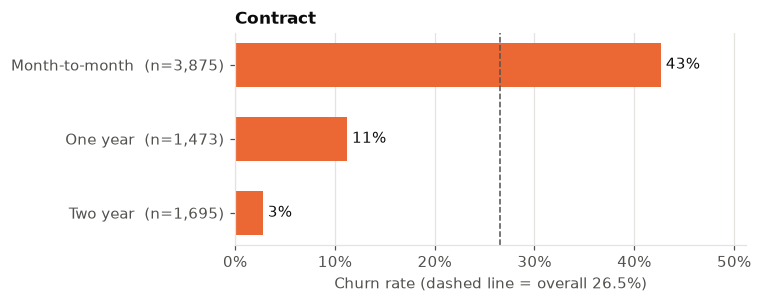

In [8]:
plot_churn_rate(df, "Contract")
plt.show()

Contract is the clearest signal in the data. **Month-to-month customers churn at 42.7%**, two-year customers at only **2.8%**, about 15× less. Month-to-month is also the largest group (55% of customers).

Leaving costs a month-to-month customer nothing, so a discount for moving to a longer contract is an obvious retention offer. *Caveat:* this is a correlation, not proof of cause. Loyal customers may simply choose longer contracts.

### 2.3 Which other features matter?

To compare all 16 categorical features at once, we take the **gap between the highest and lowest churn rate** within each feature. A large gap means the feature separates churners well.

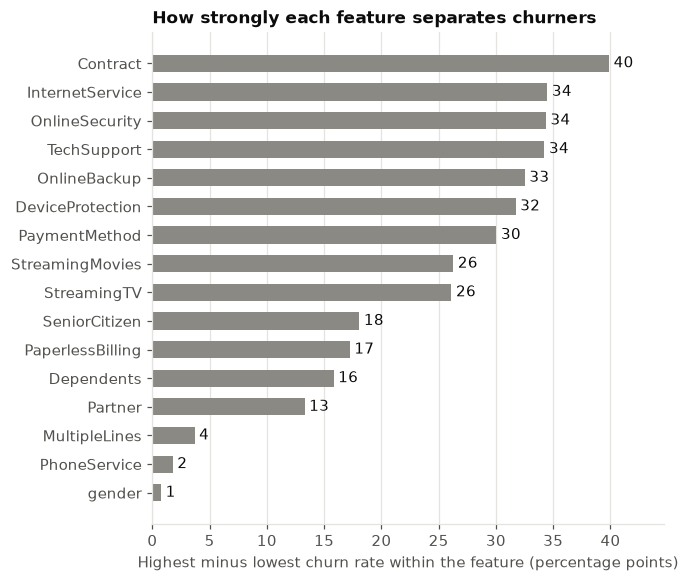

In [9]:
plot_churn_rate_gaps(churn_rate_gaps(df, CATEGORICAL_COLUMNS))
plt.show()

OnlineSecurity, TechSupport, OnlineBackup and DeviceProtection show the same pattern, so we look at one of them, together with the other strongest features:

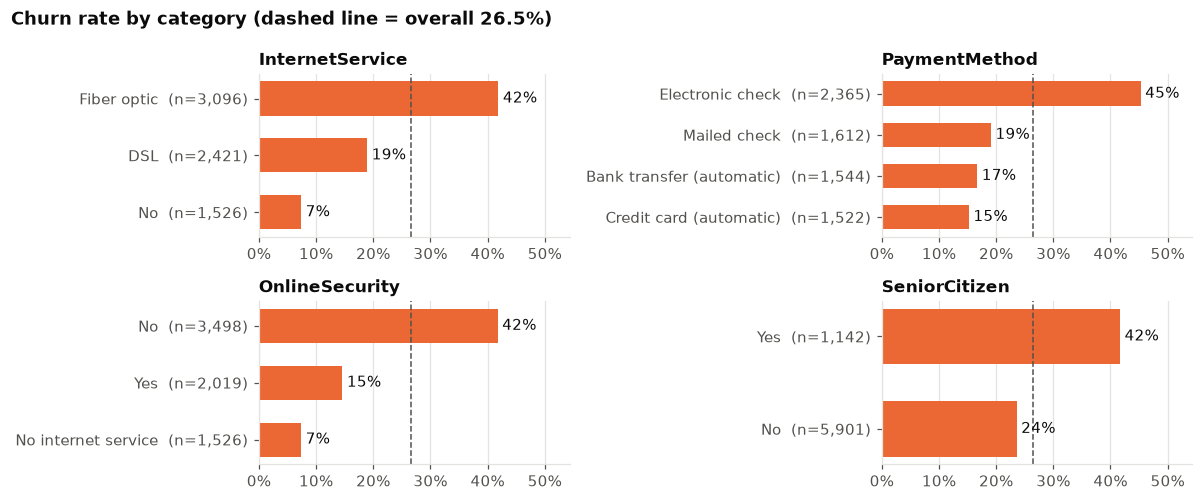

In [10]:
plot_churn_rate_grid(
    df, ["InternetService", "PaymentMethod", "OnlineSecurity", "SeniorCitizen"], ncols=2
)
plt.show()

**Higher churn:** fiber optic internet (41.9% vs 19.0% for DSL), paying by electronic check (45.3% vs 15–17% for automatic payments), no online security (41.8% vs 14.6% with it; tech support, backup and device protection look the same), and senior citizens (41.7% vs 23.6%).

**Barely matters:** gender, PhoneService and MultipleLines (under 4 points). We keep them anyway, since the model can learn to ignore them.

*Note:* the six add-on columns all include a "No internet service" category. It's the same 1,526 customers in each, with only 7.4% churn, and it makes their gaps look larger. Among internet customers, streaming yes vs no differs by only 3–4 points.

### 2.4 Numeric features

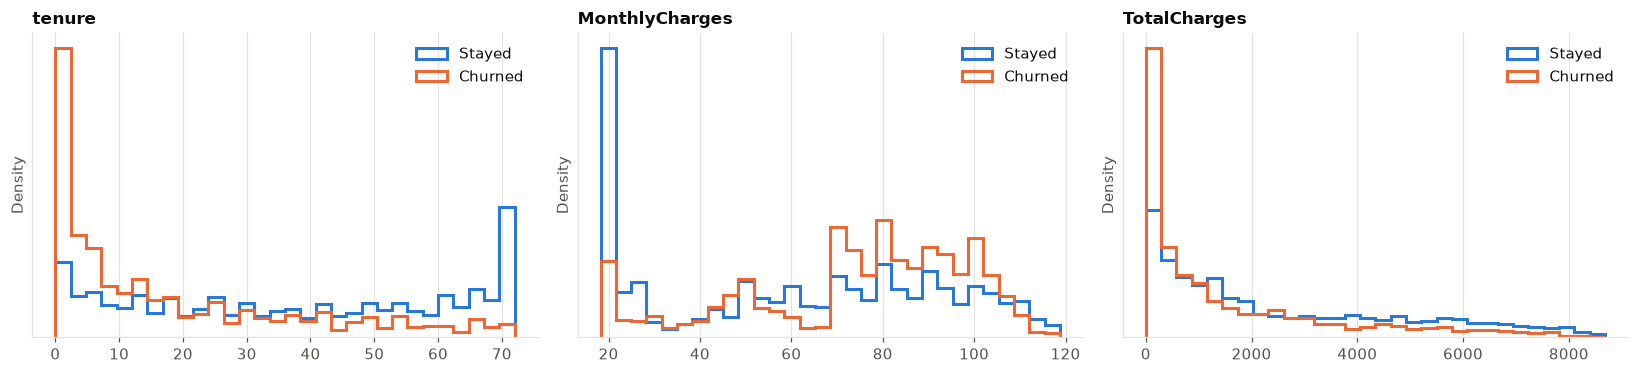

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, column in zip(axes, NUMERIC_COLUMNS):
    plot_numeric_by_churn(df, column, ax=ax)
fig.tight_layout()
plt.show()

In [12]:
total_vs_product = df["TotalCharges"].corr(df["tenure"] * df["MonthlyCharges"])
print(f"TotalCharges vs tenure × MonthlyCharges, correlation: {total_vs_product:.3f}")
df.groupby(TARGET)[NUMERIC_COLUMNS].median().rename(index={0: "Stayed", 1: "Churned"})

TotalCharges vs tenure × MonthlyCharges, correlation: 1.000


,tenure,MonthlyCharges,TotalCharges
Churn,,,
Stayed,38.0,64.425,1679.525
Churned,10.0,79.650,703.550


- **Churners leave early:** median tenure is 10 months, vs 38 for customers who stayed.
- **Churners pay more per month:** median 79.65 vs 64.43. The big group at about 20 per month (phone only, no internet) rarely churns.
- **TotalCharges adds almost nothing new:** it is practically tenure × MonthlyCharges (correlation 1.0), and it's lower for churners only because they leave sooner.

### Summary

- **Imbalanced target (26.5%):** stratified CV and churn-focused metrics instead of accuracy.
- **Highest risk:** new, month-to-month, fiber-optic customers paying by electronic check, without add-ons like online security or tech support.
- **TotalCharges** mostly repeats tenure × MonthlyCharges.

## 3. Feature engineering and preprocessing

We add two new features, then scale and encode everything. All of it is packaged in one scikit-learn pipeline (`build_preprocessor`), so that:
- in cross-validation, the scaler is re-fitted on the training folds only (no leakage);
- the REST API can pass raw customer data straight to the saved model, with no separate copy of the feature code.

### 3.1 New features

| Feature | Definition | Idea |
|---|---|---|
| AvgMonthlyCharges | TotalCharges / tenure (for new customers, with tenure 0: their MonthlyCharges) | the average amount actually paid per month |
| NumAddons | how many of the 6 add-on services the customer has | more services, more reasons to stay |

In [13]:
X_feat = add_features(X)

# new customers can't be divided by 0 months, so they get their current MonthlyCharges
new_customers = X_feat["tenure"] == 0
X_feat.loc[
    new_customers, ["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlyCharges"]
].head(3)

,tenure,MonthlyCharges,TotalCharges,AvgMonthlyCharges
488,0,52.55,0.0,52.55
753,0,20.25,0.0,20.25
936,0,80.85,0.0,80.85


In [14]:
avg, monthly = X_feat["AvgMonthlyCharges"], X_feat["MonthlyCharges"]
print(f"AvgMonthlyCharges vs MonthlyCharges, correlation: {avg.corr(monthly):.3f}")
print(f"Price change vs churn, correlation: {(monthly - avg).corr(y):.3f}")

AvgMonthlyCharges vs MonthlyCharges, correlation: 0.996
Price change vs churn, correlation: 0.002


**AvgMonthlyCharges** turns out to be almost the same as MonthlyCharges (correlation 0.996): TotalCharges in this dataset contains no real price history. We also tried the **price change** (current price minus the average paid), but it has no relation to churn (0.002), so we didn't add it. We keep AvgMonthlyCharges as the brief's example feature, without expecting much from it.

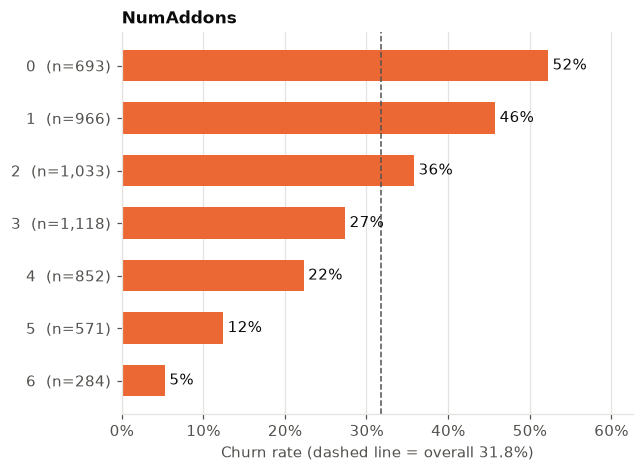

In [15]:
# internet customers only: customers without internet can't have add-ons
df_feat = X_feat.assign(**{TARGET: y})
plot_churn_rate(
    df_feat[df_feat["InternetService"] != "No"], "NumAddons", sort_by_rate=False
)
plt.show()

**NumAddons** is a strong feature: among internet customers, **churn falls with every extra add-on**, from 52% with none to 5% with all six. Customers without internet always have 0 add-ons and rarely churn (7.4%, see 2.3), so mixing them in would hide this pattern. The model can still tell the two groups apart through InternetService.

### 3.2 Scaling and encoding

| Columns | Transformer | Why |
|---|---|---|
| 3 numeric + 2 new | `StandardScaler` | rescales to mean 0 and std 1. The ranges differ a lot (tenure 0–72, TotalCharges 0–8,700), and logistic regression's regularisation penalises all coefficients equally |
| 16 categorical | `OneHotEncoder` | one 0/1 column per category. Numbering the categories 0, 1, 2 would invent an order between them |

Encoder settings: `drop="if_binary"` turns a yes/no column into one column instead of two. `handle_unknown="ignore"` encodes an unseen category as all zeros instead of crashing, which for a yes/no column means "No", so the API must validate its inputs (section 6).

In [16]:
# fitted on all data only to inspect the result
X_ready = build_preprocessor().set_output(transform="pandas").fit_transform(X)
print(f"{X.shape[1]} raw columns -> {X_ready.shape[1]} numeric columns")
print(f"missing values: {X_ready.isna().sum().sum()}")
X_ready.head(3)

19 raw columns -> 42 numeric columns
missing values: 0


,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,numeric__AvgMonthlyCharges,numeric__NumAddons,categorical__gender_Male,categorical__SeniorCitizen_Yes,categorical__Partner_Yes,categorical__Dependents_Yes,categorical__PhoneService_Yes,...,categorical__StreamingMovies_No internet service,categorical__StreamingMovies_Yes,categorical__Contract_Month-to-month,categorical__Contract_One year,categorical__Contract_Two year,categorical__PaperlessBilling_Yes,categorical__PaymentMethod_Bank transfer (automatic),categorical__PaymentMethod_Credit card (automatic),categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check
0,-1.277445,-1.160323,-0.992611,-1.156529,-0.561776,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.066327,-0.259629,-0.172165,-0.304408,-0.020519,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.236724,-0.362660,-0.958066,-0.354049,-0.020519,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


Here the preprocessor was fitted on all the data **only to inspect the result**. In step 4 it becomes the first step of the model pipeline, and cross-validation re-fits it on the training folds each time.

## 4. Model training

1. Split off a **test set** (20%). It stays untouched until the evaluation in step 5.
2. Compare models on the **training set** with stratified 5-fold cross-validation.
3. **Main metric: PR-AUC** (average precision). It measures how well the model ranks churners above non-churners, focuses on the churn class, and doesn't depend on a decision threshold. Random guessing scores 0.265 (the churn rate), a perfect model 1.0.

In [17]:
X_train, X_test, y_train, y_test = split_train_test(X, y)
print(f"train: {len(X_train):,} customers, churn {y_train.mean():.1%}")
print(f"test:  {len(X_test):,} customers, churn {y_test.mean():.1%}")

train: 5,634 customers, churn 26.5%
test:  1,409 customers, churn 26.5%


### 4.1 Comparing models

| Model | How it works | Strength | Weakness |
|---|---|---|---|
| Logistic regression | a weighted sum of the features, turned into a probability | simple, fast, explainable | only learns simple, additive effects |
| Random forest | many decision trees on random samples of the data, averaged | finds combinations of features by itself | overfits easily, harder to explain |
| Gradient boosting | small trees added one by one, each fixing the previous ones' errors | often the most accurate on tabular data | more settings to tune, harder to explain |

Each model uses the best settings from our experiments (4.2). The random forest is also shown with default settings, to show what overfitting looks like: `train_pr_auc` is the score on the data the model was trained on, and a big gap to the validation score `test_pr_auc` means **overfitting**.

In [18]:
cv_results = cross_validate_models(candidate_models(), X_train, y_train)
cv_results[["test_roc_auc", "test_pr_auc", "test_pr_auc_std", "train_pr_auc"]].round(3)

,test_roc_auc,test_pr_auc,test_pr_auc_std,train_pr_auc
Logistic regression,0.846,0.662,0.018,0.667
Random forest (default settings),0.827,0.622,0.029,1.000
Random forest,0.847,0.664,0.022,0.750
Gradient boosting,0.849,0.667,0.022,0.701


- The **default random forest** scores a perfect **1.000 on its training data** but only **0.622 on validation**: it memorised the training customers. Requiring at least 20 customers per leaf fixes that (0.664). Judged on its training data alone, the default forest would look perfect, which is exactly why we cross-validate.
- The three tuned models are **very close** (PR-AUC 0.662 to 0.667), closer than the variation between folds (std ≈ 0.02).
- **Logistic regression** doesn't overfit at all (train 0.667 vs validation 0.662).

### 4.2 How we chose these settings

During development we ran these experiments on the training set (validation PR-AUC). They aren't repeated here, to keep the notebook fast; `scripts/model_experiments.py` reproduces them in about 4 minutes. They ran with class weights, so the numbers differ slightly from 4.1.

| Experiment | Result |
|---|---|
| **Hyperparameter search** (33 settings for logistic regression, 30 each for the tree models) | Logistic regression barely changes (0.658 → 0.661). The tree models gain the most by being **restricted**: random forest 0.616 → 0.666, gradient boosting 0.645 → 0.668 with depth-2 trees |
| **Nested CV** (the search repeated inside each fold) | 0.660 / 0.664 / 0.664: the tree models' search scores were slightly flattered |
| **Ensemble** of logistic regression and gradient boosting | best overall (0.669), but less than 0.01 ahead of logistic regression |
| **Class weights** (`"balanced"` vs none) | same ranking quality, but the average predicted probability is **41%** instead of the real **26.5%**, so we use **no class weights** |
| **Engineered features** (with vs without) | no measurable difference: the model can already compute NumAddons from the add-on columns, and AvgMonthlyCharges ≈ MonthlyCharges |

The best tree models use very shallow trees, so they are close to a simple additive model: churn here is mostly explained by simple effects (contract, tenure, internet type), which logistic regression already captures.

### 4.3 Final choice: logistic regression

We choose **L1-regularised logistic regression** (`C = 0.3`, no class weights):
1. **Practically as accurate:** the best alternative is less than 0.01 PR-AUC better, less than the variation between folds.
2. **Explainable:** one weight per feature, so the sales team can see *why* a customer is flagged.
3. **Robust and simple:** it doesn't overfit, and it trains in a fraction of a second.
4. **Honest probabilities:** without class weights, a "70% churn risk" really means about 70%.

*Caveat:* some one-hot columns repeat each other (the six "No internet service" columns), so single coefficients must be read with care. Step 5 explains the model with permutation importance instead.

In [19]:
# train on the full training set and save the whole pipeline (preprocessing + model);
# models/churn_model.joblib isn't committed to git, this cell recreates it
model = train_model(candidate_models()["Logistic regression"], X_train, y_train)
save_model(model)

# sanity check: the saved model loads and returns churn probabilities for raw customer data
load_model().predict_proba(X_train.head(3))[:, 1].round(3)

array([0.333, 0.288, 0.046])

## 5. Model evaluation

1. **Which decision threshold?** Chosen on the training set only.
2. **How good is the model?** Measured **once** on the test set, which hasn't been used so far.
3. **What drives its predictions?**

### 5.1 Choosing the decision threshold

The model outputs a churn **probability**; the sales team needs a **yes/no list**. A threshold turns one into the other: a customer is flagged if their probability ≥ threshold. The default of 0.5 is arbitrary.

**Our rule: catch at least 75% of churners, with the best possible precision.** Losing a customer usually costs more than an incentive offered to someone who would have stayed anyway, so recall matters more than precision.

To keep the test set untouched, the threshold is chosen on **out-of-fold** predictions for the training set: each customer is predicted by a model that didn't see them during training.

Chosen threshold: 0.31


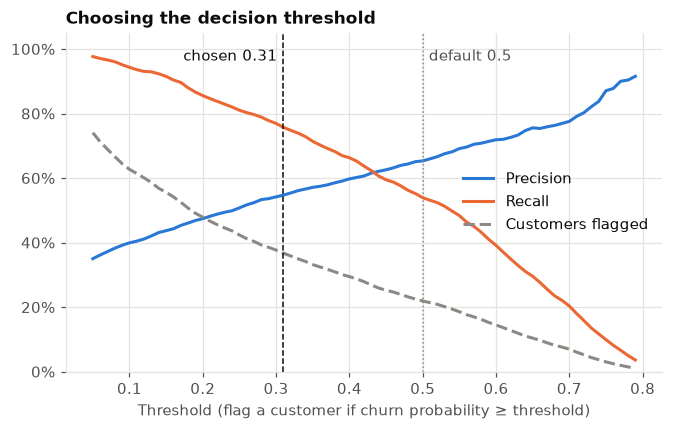

,precision,recall,f1,flagged_share
threshold,,,,
0.31,0.547,0.757,0.635,0.367
0.50,0.653,0.539,0.591,0.219


In [20]:
oof_proba = out_of_fold_proba(
    candidate_models()["Logistic regression"], X_train, y_train
)
threshold = choose_threshold(y_train, oof_proba, min_recall=0.75)
table = threshold_table(y_train, oof_proba)

print(f"Chosen threshold: {threshold}")
plot_threshold_tradeoff(table, threshold)
plt.show()
table.loc[[threshold, 0.5]].round(3)

With threshold **0.31** we flag 37% of customers and catch **76% of churners**, and 55% of the flagged customers really churn. At the default 0.5 we would catch only 54% of churners, missing almost half. (The threshold with the best F1 score, 0.33, is almost the same.)

### 5.2 Test set results

The test set (1,409 customers) is used **once**, with the threshold fixed above.

In [21]:
test_proba = model.predict_proba(X_test)[:, 1]

pd.DataFrame(
    {
        "threshold 0.5": evaluation_metrics(y_test, test_proba, 0.5),
        f"threshold {threshold}": evaluation_metrics(y_test, test_proba, threshold),
    }
).round(3)

,threshold 0.5,threshold 0.31
roc_auc,0.842,0.842
pr_auc,0.636,0.636
precision,0.647,0.529
recall,0.553,0.746
f1,0.597,0.619
accuracy,0.801,0.757


- **Ranking quality:** ROC-AUC **0.842** and PR-AUC **0.636** (random guessing: 0.265). Slightly below the cross-validation estimate (0.846 and 0.662), but within the variation between folds (std ≈ 0.02). We don't tune further, because that would turn the test set into training data.
- **At threshold 0.31:** recall **0.746**, so we reach 3 of every 4 churners, and precision **0.529**, so about half of the customers we contact would really have left. At 0.5, recall is only 0.553.
- **Accuracy drops** from 0.801 to 0.757 because we flag more customers. That's expected: accuracy rewards predicting "stays", which is exactly what we don't want.

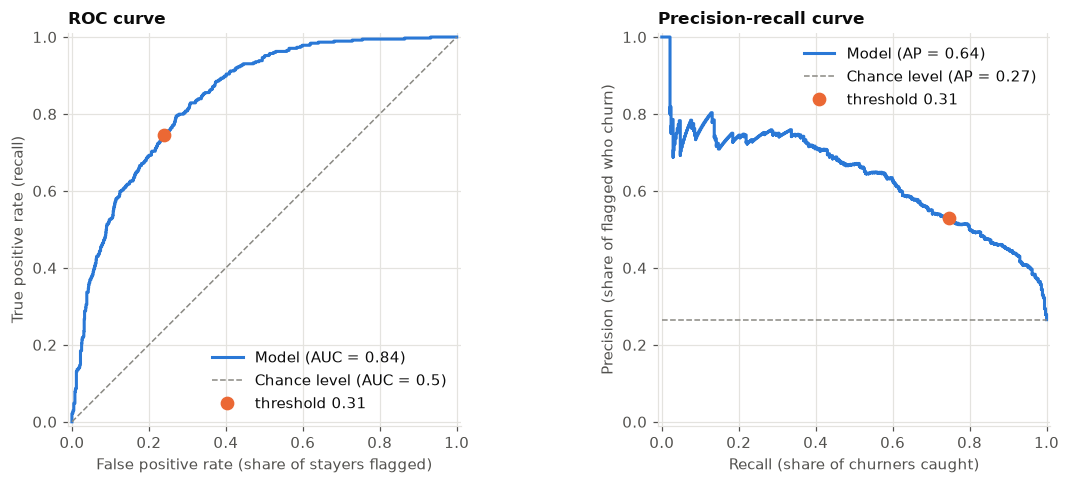

In [22]:
plot_roc_pr_curves(y_test, test_proba, threshold)
plt.show()

- **ROC curve:** an AUC of 0.84 means that for a random churner and a random non-churner, the model gives the churner the higher risk 84% of the time (random guessing: 50%).
- **Precision-recall curve:** far above the random baseline of 0.27. Catching more churners (moving right) costs precision. The dot is our threshold.

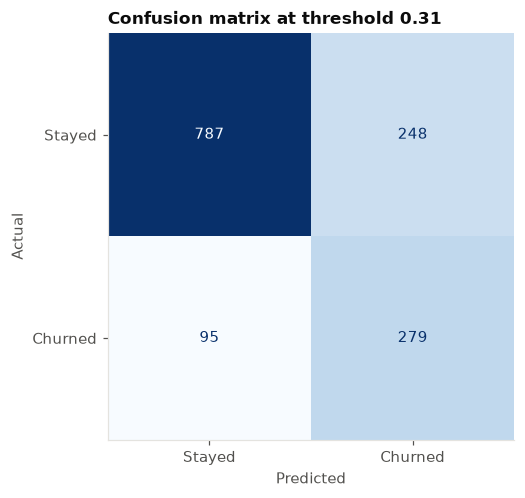

In [23]:
plot_confusion_matrix(y_test, test_proba, threshold)
plt.show()

In [24]:
# with a fixed campaign budget: contact the riskiest customers first
top_20 = test_proba >= np.quantile(test_proba, 0.8)
caught = y_test[top_20].sum() / y_test.sum()
print(f"The 20% riskiest customers include {caught:.0%} of all churners")

The 20% riskiest customers include 51% of all churners


Of the **374** test customers who churned, the model catches **279** and misses **95**. It also flags **248** customers who stayed: the cost of a recall-first rule, in incentives for customers who would have stayed anyway.

With a smaller budget, the ranking still helps: the **20% riskiest** customers include **half of all churners**.

### 5.3 Are the probabilities honest?

We split the test customers into 10 equal groups by predicted probability and compare each group's average prediction with its actual churn rate.

Average prediction: 26.8%, actual rate: 26.5%


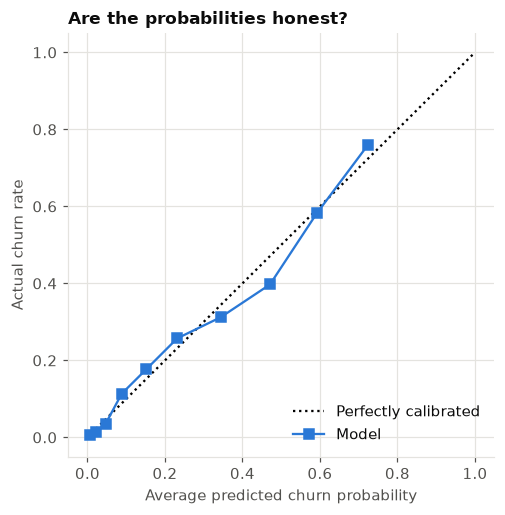

In [25]:
print(f"Average prediction: {test_proba.mean():.1%}, actual rate: {y_test.mean():.1%}")
plot_calibration(y_test, test_proba)
plt.show()

The points lie close to the diagonal, and the average prediction (26.8%) matches the actual churn rate (26.5%). So the sales team can read the probability directly: of customers scored around 60%, about 60% churn.

### 5.4 What drives the predictions?

**Permutation importance:** shuffle one feature's values between test customers and measure how much PR-AUC drops. The model is a pipeline that takes the raw columns, so each original feature is measured as a whole (Contract, not its three one-hot columns).

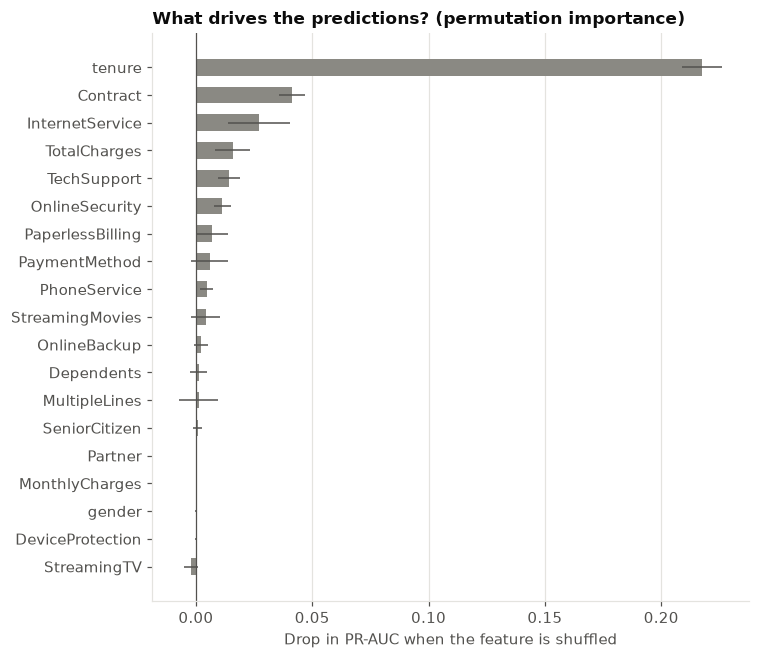

In [26]:
importances = feature_importance(model, X_test, y_test)
plot_feature_importance(importances)
plt.show()

- **tenure** matters by far the most (PR-AUC drops by 0.22 when it's shuffled): new customers are the most likely to leave.
- Next come **Contract**, **InternetService**, **TotalCharges**, **TechSupport** and **OnlineSecurity**, the same drivers the EDA found.
- **gender**, **Partner** and **MonthlyCharges** have practically no effect; the L1 penalty switched off Partner, MonthlyCharges and AvgMonthlyCharges completely. Price still matters, but its information is already in InternetService (fiber costs more) and in TotalCharges together with tenure.

*Caveat:* when two features carry the same information, shuffling one leaves the other, so both can look less important than they really are.

### 5.5 Summary

| Test set (1,409 customers) | Value |
|---|---|
| ROC-AUC | 0.842 |
| PR-AUC | 0.636 (random guessing: 0.265) |
| Recall at threshold 0.31 | 0.746 |
| Precision at threshold 0.31 | 0.529 |
| F1 at threshold 0.31 | 0.619 |

**In business terms:** contacting the 37% of customers the model flags reaches **3 of every 4 customers who would leave**, and about half of those contacted are real churn risks. The strongest signals are **short tenure, a month-to-month contract, fiber internet, and no tech support or online security**, which also suggests what to offer: a discount for a longer contract, or free tech support or security add-ons.

## 6. Serving the model through a REST API

The CRM sends customer data and gets back a churn probability and a yes/no flag for each customer. Because the saved file is the **whole pipeline** (new features, scaling, encoding and model), the API passes the raw customer fields straight to it, with no second copy of the feature code.

| Part | Design |
|---|---|
| Framework | **FastAPI**, served by uvicorn in a Docker container |
| Model | `models/churn_model.joblib` is loaded once at startup, together with the threshold (0.31) and a model version |
| `POST /predict` | one or more customers in, one prediction per customer out |
| `GET /health` | for monitoring: is the service running and the model loaded? |
| Validation | a Pydantic schema for the 19 fields: the allowed values of every category (e.g. Contract must be one of the three contract types) and tenure ≥ 0. Invalid input gets an HTTP 422 error explaining what's wrong, instead of a silently wrong prediction |
| Security | reachable only from the internal network, with an API key for the CRM |

**Example.** The CRM sends:
```json
POST /predict
{
  "customers": [
    {
      "customerID": "7590-VHVEG",
      "gender": "Female", "SeniorCitizen": "No", "Partner": "Yes", "Dependents": "No",
      "tenure": 1, "PhoneService": "No", "MultipleLines": "No phone service",
      "InternetService": "DSL", "OnlineSecurity": "No", "OnlineBackup": "Yes",
      "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No",
      "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
      "MonthlyCharges": 29.85, "TotalCharges": 29.85
    }
  ]
}
```
and gets back:
```json
{
  "model_version": "2026-10-27",
  "threshold": 0.31,
  "predictions": [{"customerID": "7590-VHVEG", "churn_probability": 0.59, "flag": true}]
}
```
customerID is returned so the CRM can match the results, but it isn't given to the model.

**The core of the endpoint** would be only a few lines:
```python
app = FastAPI()
model = load_model()
THRESHOLD = 0.31

@app.post("/predict")
def predict(request: PredictRequest) -> PredictResponse:
    customers = pd.DataFrame([customer.model_dump() for customer in request.customers])
    proba = model.predict_proba(customers.drop(columns="customerID"))[:, 1]
    return PredictResponse(predictions=[
        Prediction(customerID=cid, churn_probability=round(p, 3), flag=p >= THRESHOLD)
        for cid, p in zip(customers["customerID"], proba)
    ])
```

**In operation:**
- **Batch scoring:** since we predict churn for the *next month*, the CRM can also send all customers once a week or month in one call, instead of asking about customers one at a time.
- **Monitoring:** log inputs and predictions, compare the predicted churn rate with the actual one each month, and watch for changes in the input data.
- **Retraining:** retrain regularly on fresh data with the same pipeline, save each model file with a new version, and review the threshold with the sales team.